In [1]:
# 环境使用panxf环境
# 这里导入包
# d2l是李沐《动手学深度学习》的代码，可以使用其中的函数
# 代码的风格尽量贴近d2l中的代码风格，不要使用语法糖等复杂的python语法，pytorch语法请使用d2l内使用过的

import sys
import warnings
sys.path.append('../SubspaceNet-main')
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import numpy as np
from tqdm import tqdm
import d2l

from src.criterions import RMSPELoss, RMSPE
from src.methods import RootMUSIC, Esprit
from src.system_model import SystemModel, SystemModelParams
from src.utils import R2D

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch 版本:", torch.__version__)
print("使用设备:", device)

torch 版本: 2.6.0+cu118
使用设备: cuda


In [2]:
# 导入数据，数据是按照同一文件夹下的subspacenet生成的。请使用Generic前缀的数据集。
# 简单介绍一下该数据集，数据集内每一个量是一个元组，元组内有原始的快拍数据和标签
# 数据集由 SubspaceNet 的数据生成代码创建，每个样本是一个元组 (X, doa)：
#   X:   阵列接收的原始快拍，形状 (N, T)，复数张量。N=8 个阵元，T=100 个快拍
#   doa: M 个真实来波方向，形状 (M,)，浮点数，单位是弧度。M=3 个完全相干的源
# 文件虽然以 .h5 结尾，但实际是用 torch.save 保存的列表，要用 torch.load 读取

import os

def find_file(folder, prefix):
    """在文件夹中找到以 prefix 开头的第一个文件"""
    for name in os.listdir(folder):
        if name.startswith(prefix):
            return folder + "/" + name
    raise FileNotFoundError("没有找到以 " + prefix + " 开头的文件")

data_dir = "data/uniform_bias_spacing"
train_file = find_file(data_dir + "/train", "Generic_DataSet")
test_file = find_file(data_dir + "/test", "Generic_DataSet")

train_dataset = torch.load(train_file)
test_dataset = torch.load(test_file)

train_dataset = train_dataset[:10000]

print("训练集样本数:", len(train_dataset))
print("测试集样本数:", len(test_dataset))
X, doa = train_dataset[0]
print("X 形状:", X.shape, " X 类型:", X.dtype)
print("doa 形状:", doa.shape, " doa 类型:", doa.dtype)
print("第一个样本的真实 DOA（度）:", doa.numpy() * R2D)

训练集样本数: 10000
测试集样本数: 5000
X 形状: torch.Size([8, 100])  X 类型: torch.complex64
doa 形状: torch.Size([3])  doa 类型: torch.float64
第一个样本的真实 DOA（度）: [-22.58  41.76  81.13]


In [5]:
# 写网络架构，网络先使用基础版的transformer编码器。后续的子协方差头和位置嵌入先空下主要看编码器能够起到多大作用
# 输入使用原始快拍数据，embedding使用最基础的嵌入，编码器层使用三层，网络后端使用可微的ESPRIT进行
# 损失函数按照subspacenet的RMSEP进行，你可以将该函数进行import
# 基础版结构：
#   前端：每个阵元当作一个 token（空间注意力），特征是该阵元 T 个快拍的实部加虚部
#   中间：线性嵌入 + 标准正弦余弦位置编码 + 3 层 Transformer 编码器块
#   后端：编码器输出映射成复特征 F，构造 Rz = F^H F + eps*I（厄密特化），再送可微 ESPRIT
#
# 后端 ESPRIT 的修复（相对原版 src.models.esprit，共五处）：
#   1. 批量实现：一次 eig 处理整个批次，不再逐样本循环（速度大幅提升）
#   2. 相位规整：把每个特征向量旋转到"第一个元素为正实数"，让下游对特征向量
#      的相位精确不变，相位检查量降到舍入级别
#   3. phi 用解方程代替伪逆：phi = solve(Uu^H Uu, Uu^H Ul)，数值更稳
#   4. SafeAngle：torch.angle 的反向在 z 接近 0 时按 1/|z| 爆炸（两个源很近或
#      训练初期 ESPRIT 特征值会接近 0），巨大梯度会让 eig 的反向检查误报
#      "ill-defined"，这里把放大钳制在约 1/(2*sqrt(eps)) 以内
#   5. arcsin 输入裁剪：DOA 接近正负 90 度时 1/sqrt(1-x^2) 会无穷大产生 NaN

class SafeAngle(torch.autograd.Function):
    """数值稳定的角度函数：前向与 torch.angle 相同，反向把放大钳制住

    torch.angle 的反向公式是 gz = g * z / |z|^2 * (-1j)，当 z 接近 0 时
    梯度按 1/|z| 爆炸（ESPRIT 的特征值可能接近 0，例如两个源的角度很接近时）。
    分母加一个很小的 eps，把放大上限压到约 1/(2*sqrt(eps))。
    """

    @staticmethod
    def forward(ctx, z):
        ctx.save_for_backward(z)
        return torch.angle(z)

    @staticmethod
    def backward(ctx, g):
        z, = ctx.saved_tensors
        eps = 1e-5
        gz = g * z / (z.abs().pow(2) + eps) * (1j)
        return gz


def esprit_differentiable(Rz, M, batch_size):
    """批量可微 ESPRIT（修复版）

    输入: Rz，形状 (batch_size, N, N) 的复数协方差矩阵
    输出: doa，形状 (batch_size, M)，单位是弧度
    """
    N = Rz.shape[1]
    eigenvalues, eigenvectors = torch.linalg.eig(Rz)
    # 按特征值模长降序取前 M 个特征向量作为信号子空间
    idx = torch.argsort(torch.abs(eigenvalues), dim=1, descending=True)
    Us = torch.gather(eigenvectors, 2,
                      idx[:, :M].unsqueeze(1).expand(-1, N, -1))
    # 相位规整：把每个特征向量旋转到"第一个元素为正实数"
    phase = SafeAngle.apply(Us[:, 0, :])
    Us = Us * torch.exp(-1j * phase).unsqueeze(1)
    # 拆成两个平移子阵
    Us_upper = Us[:, :-1, :]
    Us_lower = Us[:, 1:, :]
    # phi = pinv(Us_upper) @ Us_lower，改用解方程，数值更稳
    gram = Us_upper.conj().transpose(1, 2) @ Us_upper
    phi = torch.linalg.solve(gram,
                             Us_upper.conj().transpose(1, 2) @ Us_lower)
    # 只取 phi 的特征值（不使用特征向量，不触发特征向量相关的检查）
    phi_eigenvalues, _ = torch.linalg.eig(phi)
    # 角度换算成 DOA：SafeAngle 防 z≈0 的梯度爆炸，裁剪防边界 NaN
    eigenvalues_angels = SafeAngle.apply(phi_eigenvalues)
    x = torch.clamp(eigenvalues_angels / np.pi, -0.9999, 0.9999)
    doa_predictions = -1 * torch.arcsin(x)
    return doa_predictions


class TransformerDOA(nn.Module):
    """基于 Transformer 编码器的 DOA 估计网络（基础版）

    输入: X，形状 (batch_size, N, T) 的复数快拍
    输出: doa，形状 (batch_size, M)，单位是弧度
    """

    def __init__(self, N, T, M, num_hiddens, num_heads, ffn_num_hiddens,
                 num_layers, dropout):
        super(TransformerDOA, self).__init__()
        self.N = N
        self.M = M
        # 每个阵元一个 token，特征是该阵元 T 个快拍的实部与虚部拼接
        self.embedding = nn.Linear(2 * T, num_hiddens)
        # 标准正弦余弦位置编码，让网络知道阵元的排列顺序
        # 阵列几何位置编码（用物理坐标）留到后续单元格
        self.pos_encoding = d2l.PositionalEncoding(num_hiddens, dropout)
        # num_layers 层编码器块
        self.blks = nn.Sequential()
        for i in range(num_layers):
            self.blks.add_module(
                "block" + str(i),
                d2l.EncoderBlock(num_hiddens, num_hiddens, num_hiddens,
                                 num_hiddens, [num_hiddens], num_hiddens,
                                 ffn_num_hiddens, num_heads, dropout))
        # 输出层：把每个 token 映射成复特征 F 的实部和虚部，F 形状为 (N, N)
        self.output_layer = nn.Linear(num_hiddens, 2 * N)
        # 记录各层注意力权重，供可视化单元格使用
        self.attention_weights = [None] * num_layers
        self.Rz = None

    def forward(self, X):
        batch_size = X.shape[0]
        # 实部虚部拼接: (batch_size, N, 2T)
        features = torch.cat((torch.real(X), torch.imag(X)), dim=2)
        # 逐样本标准化，稳定训练
        mean = features.mean(dim=(1, 2), keepdim=True)
        std = features.std(dim=(1, 2), keepdim=True) + 1e-6
        features = (features - mean) / std
        # 嵌入加位置编码
        X = self.pos_encoding(self.embedding(features))
        # 逐层编码并记录注意力权重
        for i, blk in enumerate(self.blks):
            X = blk(X, None)
            self.attention_weights[i] = blk.attention.attention.attention_weights
        # 复特征 F: (batch_size, N, N)
        out = self.output_layer(X)
        F = torch.complex(out[:, :, :self.N], out[:, :, self.N:])
        # 厄密特化: Rz = F^H F + eps * I，保证 Hermitian 且半正定
        eps = 1.0
        Rz = torch.bmm(F.conj().transpose(1, 2), F)
        eye = torch.eye(self.N, device=X.device)
        Rz = Rz + eps * eye.unsqueeze(0)
        self.Rz = Rz
        # 可微 ESPRIT 后端（修复版），输出 (batch_size, M)
        doa = esprit_differentiable(Rz, self.M, batch_size)
        return doa

In [ ]:
# 编写网络的训练及验证。建议导入d2l包中的函数进行
# 训练集和验证集按照8：2进行。
# 使用d2l的训练可视化函数进行时时迭代
# 先取前 10000 个训练样本按 8:2 切分（快速迭代用），收敛后再换回全量数据：
# 把 train_dataset[:10000] 换回 train_dataset 即可
# 用 tqdm 显示每个 epoch 的进度（仿 SubspaceNet），训练结束后统一画曲线
# 反向传播后做梯度裁剪：防止训练初期 Rz≈I（特征值近简并）导致的梯度爆炸
# 注意：梯度裁剪救不了 "ill-defined" 报错（那个错在 backward 内部抛出），
#      那个问题已在单元格 2 的 esprit_differentiable 里修复

# 只取前 10000 个样本（快速迭代用，收敛后再换回全量数据）
subset = train_dataset[:10000]
X_all = []
Y_all = []
for x, y in subset:
    X_all.append(x)
    Y_all.append(y)
X_all = torch.stack(X_all, dim=0)
Y_all = torch.stack(Y_all, dim=0).float()

# 打乱顺序
perm = torch.randperm(X_all.shape[0])
X_all = X_all[perm]
Y_all = Y_all[perm]

# 8:2 切分
num_train = int(X_all.shape[0] * 0.8)
X_train, Y_train = X_all[:num_train], Y_all[:num_train]
X_val, Y_val = X_all[num_train:], Y_all[num_train:]
print("训练样本:", X_train.shape[0], " 验证样本:", X_val.shape[0])

# 数据迭代器
batch_size = 256
train_iter = d2l.load_array((X_train, Y_train), batch_size, is_train=True)
val_iter = d2l.load_array((X_val, Y_val), batch_size, is_train=False)

# 网络、损失与优化器
num_hiddens = 64
num_heads = 4
ffn_num_hiddens = 128
num_layers = 3
dropout = 0.1
lr = 0.001
num_epochs = 20
max_norm = 10.0

net = TransformerDOA(N=8, T=100, M=3, num_hiddens=num_hiddens,
                     num_heads=num_heads, ffn_num_hiddens=ffn_num_hiddens,
                     num_layers=num_layers, dropout=dropout)
net.to(device)
loss = RMSPELoss()
updater = torch.optim.Adam(net.parameters(), lr=lr)

# 训练与验证
train_loss_list = []
val_loss_list = []
for epoch in range(num_epochs):
    # 训练
    net.train()
    train_sum = 0.0
    train_num = 0
    for X, y in tqdm(train_iter, desc="epoch " + str(epoch + 1), leave=False):
        X = X.to(device)
        y = y.to(device)
        updater.zero_grad()
        l = loss(net(X), y)
        l.backward()
        # 梯度裁剪（backward 之后、更新参数之前）
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm)
        updater.step()
        train_sum = train_sum + float(l.detach().cpu())
        train_num = train_num + y.shape[0]
    # 验证
    net.eval()
    val_sum = 0.0
    val_num = 0
    with torch.no_grad():
        for X, y in val_iter:
            X = X.to(device)
            y = y.to(device)
            l = loss(net(X), y)
            val_sum = val_sum + float(l.cpu())
            val_num = val_num + y.shape[0]
    train_rmspe = train_sum / train_num
    val_rmspe = val_sum / val_num
    train_loss_list.append(train_rmspe)
    val_loss_list.append(val_rmspe)
    print("epoch", epoch + 1, " train RMSPE:", round(train_rmspe, 4),
          " val RMSPE:", round(val_rmspe, 4))

# 训练结束后画出损失曲线
fig, ax = d2l.plt.subplots(figsize=(6, 4))
ax.plot(range(1, num_epochs + 1), train_loss_list, '-', label='train loss')
ax.plot(range(1, num_epochs + 1), val_loss_list, 'm--', label='val loss')
ax.set_xlabel('epoch')
ax.set_ylabel('RMSPE (rad)')
ax.legend()
d2l.plt.show()

训练样本: 8000  验证样本: 2000


epoch 1:  50%|█████     | 16/32 [00:07<00:07,  2.13it/s]

In [ ]:
# 编写网络的评估。建议和训练进行配套
# 评估要求对函数的loss进行评估，对比方法为sps-r-music以及sps-r-esprit。这部分代码可以从subspacenet中获取，可导入
# 三种方法统一用"度"为单位、numpy 版 RMSPE 作为评价指标
# 经典基线逐样本计算，5000 个样本可能需要几十秒，请耐心等待

np.random.seed(0)

def pad_predictions(predictions, M):
    """预测数量不足 M 时用随机角度补齐，保证 RMSPE 长度一致"""
    if len(predictions) >= M:
        return predictions
    padded = []
    for p in predictions:
        padded.append(p)
    for i in range(M - len(predictions)):
        padded.append(np.random.uniform(-90, 90))
    return np.array(padded)

# 1. 网络在测试集上的 RMSPE（批量计算）
X_test = []
Y_test = []
for x, y in test_dataset:
    X_test.append(x)
    Y_test.append(y)
X_test = torch.stack(X_test, dim=0)
Y_test = torch.stack(Y_test, dim=0).float()

net.eval()
net_loss_list = []
with torch.no_grad():
    for X, y in d2l.load_array((X_test, Y_test), 256, is_train=False):
        X = X.to(device)
        pred = net(X).cpu().numpy()
        for i in range(pred.shape[0]):
            pred_deg = pred[i] * R2D
            true_deg = y[i].numpy() * R2D
            net_loss_list.append(RMSPE(pred_deg, true_deg))
net_rmspe = np.mean(net_loss_list)
print("TransformerDOA 平均 RMSPE(度):", round(net_rmspe, 4))

# 2. 经典基线 SPS-R-MUSIC 与 SPS-R-ESPRIT（逐样本，numpy 实现）
system_params = SystemModelParams()
system_params.M = 3
system_params.N = 8
system_params.T = 100
system_params.signal_nature = "coherent"
system_model = SystemModel(system_params)

root_music = RootMUSIC(system_model)
classic_esprit = Esprit(system_model)

sps_r_music_list = []
sps_esprit_list = []
for i in range(len(test_dataset)):
    X, y = test_dataset[i]
    X_np = X.numpy()
    true_deg = y.numpy() * R2D
    # SPS-R-MUSIC
    predictions, roots, predictions_all, _, M = root_music.narrowband(
        X=X_np, mode="spatial_smoothing")
    predictions = pad_predictions(predictions, 3)
    sps_r_music_list.append(RMSPE(predictions, true_deg))
    # SPS-R-ESPRIT
    predictions, M = classic_esprit.narrowband(X=X_np, mode="spatial_smoothing")
    predictions = pad_predictions(predictions, 3)
    sps_esprit_list.append(RMSPE(predictions, true_deg))

print("SPS-R-MUSIC 平均 RMSPE(度):", round(np.mean(sps_r_music_list), 4))
print("SPS-R-ESPRIT 平均 RMSPE(度):", round(np.mean(sps_esprit_list), 4))

In [ ]:
# 对网络的性能进行分析要求给出可视化
# 可视化1：对最终求出的重构协方差矩阵进行可视化，给出热力图以及特征值看是否能够识别出信源个数
# 可视化2：对样本的注意力权重进行可视化

net.eval()
num_show = 3
sample_idx = [0, 1, 2]

# 可视化1：重构协方差矩阵热力图 + 特征值（和样本协方差对比）
fig, axes = d2l.plt.subplots(num_show, 3, figsize=(13, 9))
for row in range(num_show):
    idx = sample_idx[row]
    X, y = test_dataset[idx]
    X = X.unsqueeze(0).to(device)
    with torch.no_grad():
        doa = net(X)
        Rz = net.Rz[0].cpu().numpy()
    # 样本协方差及其特征值（相干源下信号成分秩为 1，用来对比解相干效果）
    x_np = X[0].cpu().numpy()
    x_np = x_np - x_np.mean(axis=1, keepdims=True)
    R_sample = x_np @ x_np.conj().T / x_np.shape[1]
    eig_sample = np.linalg.eigvalsh(R_sample)[::-1]
    # 学习出的协方差的特征值
    eig_learned = np.linalg.eigvalsh(Rz)[::-1]
    # 热力图
    im = axes[row, 0].imshow(np.abs(Rz), cmap='hot')
    axes[row, 0].set_title('样本' + str(idx) + ' |Rz| 热力图')
    d2l.plt.colorbar(im, ax=axes[row, 0])
    # 特征值对比（前 M 个画成红色，看是否识别出信源个数）
    axes[row, 1].bar(np.arange(1, 9), eig_learned)
    axes[row, 1].bar(np.arange(1, 4), eig_learned[:3], color='red')
    axes[row, 1].set_title('样本' + str(idx) + ' 学习协方差特征值')
    axes[row, 2].bar(np.arange(1, 9), eig_sample)
    axes[row, 2].bar(np.arange(1, 4), eig_sample[:3], color='red')
    axes[row, 2].set_title('样本' + str(idx) + ' 样本协方差特征值')
    print("样本", idx, "真实 DOA(度):", np.round(y.numpy() * R2D, 2))
    print("样本", idx, "预测 DOA(度):", np.round(doa.cpu().numpy()[0] * R2D, 2))
    print("样本", idx, "学习协方差特征值:", np.round(eig_learned, 3))
    print("样本", idx, "样本协方差特征值:", np.round(eig_sample, 3))
d2l.plt.tight_layout()
d2l.plt.show()

# 可视化2：编码器各层的平均注意力权重（多个头取平均）
X, y = test_dataset[0]
X = X.unsqueeze(0).to(device)
with torch.no_grad():
    net(X)
num_layers_show = len(net.attention_weights)
fig, axes = d2l.plt.subplots(1, num_layers_show, figsize=(5 * num_layers_show, 4))
for layer in range(num_layers_show):
    w = net.attention_weights[layer]
    w = w.reshape(w.shape[0], net.N, net.N).mean(dim=0).cpu().numpy()
    im = axes[layer].imshow(w, cmap='Blues')
    axes[layer].set_title('第' + str(layer + 1) + '层平均注意力权重')
    d2l.plt.colorbar(im, ax=axes[layer])
d2l.plt.show()

train torch.Size([8000, 8, 100]) val torch.Size([2000, 8, 100])

===== 第一批逐层梯度范数 =====
embedding.weight                           2.8577e+02
embedding.bias                             1.7480e+01
blks.block0.attention.W_q.weight           8.2000e+00
blks.block0.attention.W_k.weight           8.7710e+00
blks.block0.attention.W_v.weight           6.1325e+01
blks.block0.attention.W_o.weight           6.3500e+01
blks.block0.addnorm1.ln.weight             1.5197e+01
blks.block0.addnorm1.ln.bias               1.1648e+01
blks.block0.ffn.dense1.weight              5.5616e+01
blks.block0.ffn.dense1.bias                5.8420e+00
blks.block0.ffn.dense2.weight              7.0916e+01
blks.block0.ffn.dense2.bias                1.2062e+01
blks.block0.addnorm2.ln.weight             1.5137e+01
blks.block0.addnorm2.ln.bias               1.0988e+01
blks.block1.attention.W_q.weight           6.7303e+00
blks.block1.attention.W_k.weight           7.2108e+00
blks.block1.attention.W_v.weight           3.5676

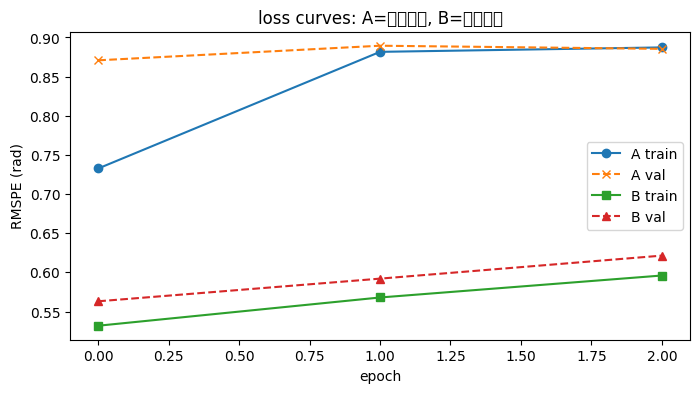

In [4]:
# ===== 诊断单元格（临时）：找出 loss 不降的原因，诊断完可以删除 =====
# 取 10000 样本 8:2 切分，对比两种训练配置，并检查逐层梯度是否真的到达网络
import numpy as np
import matplotlib.pyplot as plt

loss_fn = RMSPELoss()

# 1. 数据：前 10000 样本，8:2 切分
N_SAMPLES = 10000
subset = train_dataset[:N_SAMPLES]
X_all = []
Y_all = []
for x, y in subset:
    X_all.append(x)
    Y_all.append(y)
X_all = torch.stack(X_all, dim=0)
Y_all = torch.stack(Y_all, dim=0).float()
perm = torch.randperm(N_SAMPLES)
X_all, Y_all = X_all[perm], Y_all[perm]
X_train, Y_train = X_all[:8000], Y_all[:8000]
X_val, Y_val = X_all[8000:], Y_all[8000:]
print('train', X_train.shape, 'val', X_val.shape)

# 2. 逐层梯度检查（第一批 256 样本）
net0 = TransformerDOA(N=8, T=100, M=3, num_hiddens=64, num_heads=4,
                       ffn_num_hiddens=128, num_layers=3, dropout=0.1).to(device)
updater0 = torch.optim.Adam(net0.parameters(), lr=0.001)
X0 = X_train[:256].to(device)
y0 = Y_train[:256].to(device)
updater0.zero_grad()
l0 = loss_fn(net0(X0), y0)
l0.backward()
print()
print('===== 第一批逐层梯度范数 =====')
for name, p in net0.named_parameters():
    if p.grad is not None:
        print('%-42s %.4e' % (name, p.grad.norm().item()))
    else:
        print('%-42s None  <<< 梯度没到!' % name)
with torch.no_grad():
    doa0 = net0(X0)
print('初始预测(度): 均值 %.2f  标准差 %.2f' % (
    doa0.mean().item() * 180 / np.pi, doa0.std().item() * 180 / np.pi))
print('初始目标(度): 均值 %.2f  标准差 %.2f' % (
    y0.mean().item() * 180 / np.pi, y0.std().item() * 180 / np.pi))

# 3. 两种配置对比训练（各 3 个 epoch）
def run_config(batch_size, lr, num_epochs, tag):
    net = TransformerDOA(N=8, T=100, M=3, num_hiddens=64, num_heads=4,
                          ffn_num_hiddens=128, num_layers=3, dropout=0.1).to(device)
    updater = torch.optim.Adam(net.parameters(), lr=lr)
    train_curve = []
    val_curve = []
    for epoch in range(num_epochs):
        net.train()
        s, n = 0.0, 0
        for i in range(0, X_train.shape[0], batch_size):
            X = X_train[i:i + batch_size].to(device)
            y = Y_train[i:i + batch_size].to(device)
            updater.zero_grad()
            l = loss_fn(net(X), y)
            l.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
            updater.step()
            s += float(l.detach().cpu())
            n += y.shape[0]
        train_curve.append(s / n)
        net.eval()
        s, n = 0.0, 0
        with torch.no_grad():
            for i in range(0, X_val.shape[0], batch_size):
                X = X_val[i:i + batch_size].to(device)
                y = Y_val[i:i + batch_size].to(device)
                s += float(loss_fn(net(X), y).cpu())
                n += y.shape[0]
        val_curve.append(s / n)
        print(tag, 'epoch', epoch + 1, ' train %.4f  val %.4f' % (
            train_curve[-1], val_curve[-1]))
    return train_curve, val_curve

cA = run_config(256, 0.001, 3, 'A(256,1e-3)当前')
cB = run_config(1024, 0.0001, 3, 'B(1024,1e-4)原版配方')

plt.figure(figsize=(8, 4))
plt.plot(cA[0], 'o-', label='A train')
plt.plot(cA[1], 'x--', label='A val')
plt.plot(cB[0], 's-', label='B train')
plt.plot(cB[1], '^--', label='B val')
plt.xlabel('epoch')
plt.ylabel('RMSPE (rad)')
plt.legend()
plt.title('loss curves: A=当前配置, B=原版配方')
plt.show()

# 判读：
# 1) 某层梯度是 None/0 -> 实现 bug，把输出贴给助手
# 2) A 平、B 降 -> 优化配置问题，按 B 的 batch/lr 改单元格 3
# 3) 两条都平 -> 贴出逐层梯度数字，下一步试"输出层初始化放大"